<a href="https://colab.research.google.com/github/T1050/scg-classification/blob/main/SCG_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded:
    print(filename)

Saving CP-02-ECG.mat to CP-02-ECG.mat
Saving CP-02-SCG.mat to CP-02-SCG.mat
Saving CP-02-Vectors.mat to CP-02-Vectors (2).mat

Uploaded files:
CP-02-ECG.mat
CP-02-SCG.mat
CP-02-Vectors (2).mat


In [ ]:
!pip install -q numpy pandas scipy matplotlib neurokit2

In [ ]:
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import neurokit2 as nk

from scipy.signal import butter, filtfilt, find_peaks
from scipy.stats import median_abs_deviation

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:

import scipy.io as sio
ecg_mat = sio.loadmat(
    "CP-02-ECG.mat",
    squeeze_me=True,
    struct_as_record=False
)

scg_mat = sio.loadmat(
    "CP-02-SCG.mat",
    squeeze_me=True,
    struct_as_record=False
)

vec_mat = sio.loadmat(
    "CP-02-Vectors.mat",
    squeeze_me=True,
    struct_as_record=False
)

print("ECG loaded:", [k for k in ecg_mat if not k.startswith("__")])
print("SCG loaded:", [k for k in scg_mat if not k.startswith("__")])
print("Vectors loaded:", [k for k in vec_mat if not k.startswith("__")])

ECG loaded: ['data']
SCG loaded: ['data']
Vectors loaded: ['Shimmer_D0CD_Accel_LN_X_CAL1', 'Shimmer_D0CD_Accel_LN_Y_CAL1', 'Shimmer_D0CD_Accel_LN_Z_CAL1', 'Shimmer_D0CD_ECG_EMG_Status1_CAL1', 'Shimmer_D0CD_ECG_EMG_Status2_CAL1', 'Shimmer_D0CD_ECG_LARA_24BIT_CAL1', 'Shimmer_D0CD_ECG_LLLA_24BIT_CAL1', 'Shimmer_D0CD_ECG_LLRA_24BIT_CAL1', 'Shimmer_D0CD_ECG_VxRL_24BIT_CAL1', 'Shimmer_D0CD_Gyro_X_CAL1', 'Shimmer_D0CD_Gyro_Y_CAL1', 'Shimmer_D0CD_Gyro_Z_CAL1', 'Shimmer_D0CD_Timestamp_Shimmer_CAL1', 'None']


In [ ]:
# Extract acceleration signals
x = np.asarray(
    vec_mat["Shimmer_D0CD_Accel_LN_X_CAL1"]
).flatten().astype(float)

y = np.asarray(
    vec_mat["Shimmer_D0CD_Accel_LN_Y_CAL1"]
).flatten().astype(float)

z = np.asarray(
    vec_mat["Shimmer_D0CD_Accel_LN_Z_CAL1"]
).flatten().astype(float)

# Extract timestamps
timestamp = np.asarray(
    vec_mat["Shimmer_D0CD_Timestamp_Shimmer_CAL1"]
).flatten().astype(float)

# Extract all ECG channels
ecg_channels = {
    "LARA": np.asarray(vec_mat["Shimmer_D0CD_ECG_LARA_24BIT_CAL1"]).flatten().astype(float),
    "LLLA": np.asarray(vec_mat["Shimmer_D0CD_ECG_LLLA_24BIT_CAL1"]).flatten().astype(float),
    "LLRA": np.asarray(vec_mat["Shimmer_D0CD_ECG_LLRA_24BIT_CAL1"]).flatten().astype(float),
    "VxRL": np.asarray(vec_mat["Shimmer_D0CD_ECG_VxRL_24BIT_CAL1"]).flatten().astype(float)
}

print("X-axis:", x.shape)
print("Y-axis:", y.shape)
print("Z-axis:", z.shape)
print("Timestamp:", timestamp.shape)

for name, signal in ecg_channels.items():
    print(f"ECG {name}: {signal.shape}")

X-axis: (152864,)
Y-axis: (152864,)
Z-axis: (152864,)
Timestamp: (152864,)
ECG LARA: (152864,)
ECG LLLA: (152864,)
ECG LLRA: (152864,)
ECG VxRL: (152864,)


In [ ]:
#Calculate sampling frequency

dt = np.median(np.diff(timestamp))

fs = 1000 / dt

print("Median timestamp interval:", dt, "ms")
print("Sampling frequency:", fs, "Hz")
print("Recording duration:", len(timestamp) / fs, "seconds")

Median timestamp interval: 3.90625 ms
Sampling frequency: 256.0 Hz
Recording duration: 597.125 seconds


In [ ]:
dt = np.median(np.diff(timestamp))

fs = 1000 / dt

print("Median timestamp interval:", dt, "ms")
print("Sampling frequency:", fs, "Hz")
print("Recording duration:", len(timestamp) / fs, "seconds")

Median timestamp interval: 3.90625 ms
Sampling frequency: 256.0 Hz
Recording duration: 597.125 seconds


**Plot all ECG and SCG channels**

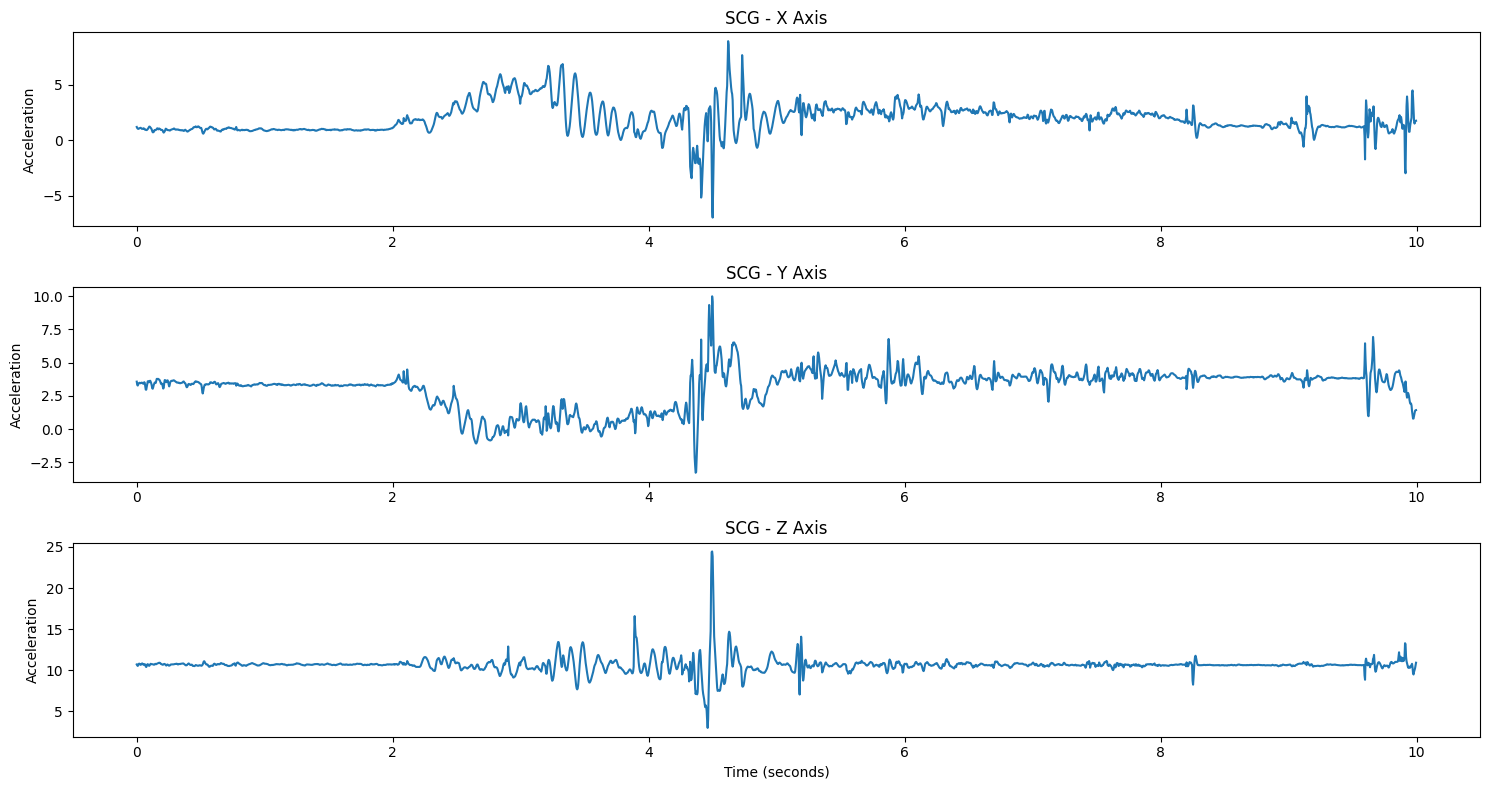

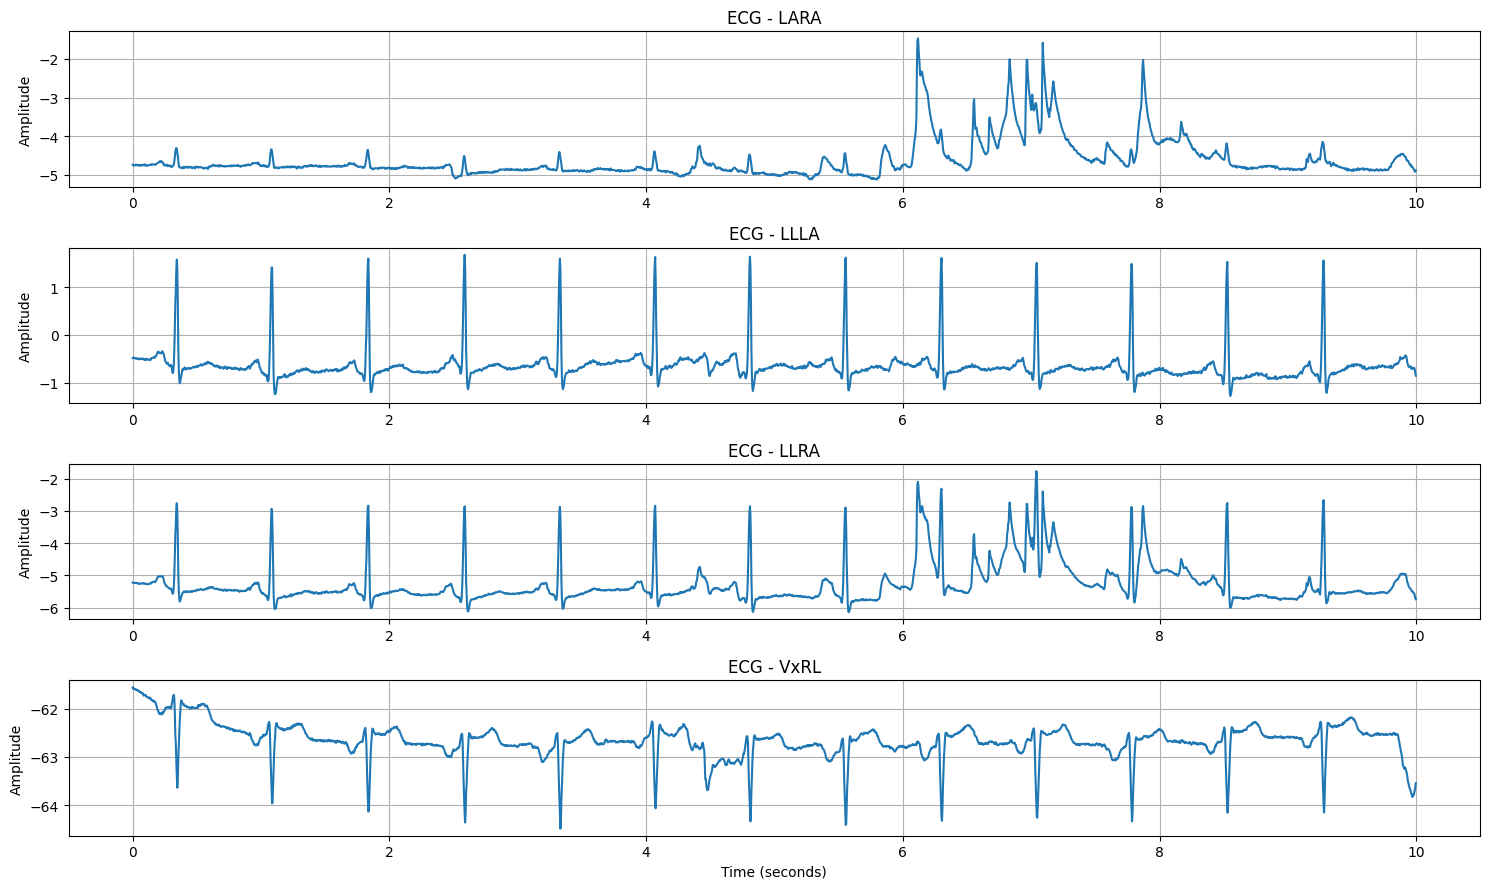

In [ ]:
duration = 10
n = int(duration * fs)
time = np.arange(n) / fs

# Plot three SCG axes
plt.figure(figsize=(15, 8))

plt.subplot(3, 1, 1)
plt.plot(time, x[:n])
plt.title("SCG - X Axis")
plt.ylabel("Acceleration")

plt.subplot(3, 1, 2)
plt.plot(time, y[:n])
plt.title("SCG - Y Axis")
plt.ylabel("Acceleration")

plt.subplot(3, 1, 3)
plt.plot(time, z[:n])
plt.title("SCG - Z Axis")
plt.ylabel("Acceleration")

plt.xlabel("Time (seconds)")
plt.tight_layout()
plt.show()


# Plot all ECG channels
plt.figure(figsize=(15, 9))

for i, (name, signal) in enumerate(ecg_channels.items(), 1):
    plt.subplot(4, 1, i)
    plt.plot(time, signal[:n])
    plt.title("ECG - " + name)
    plt.ylabel("Amplitude")
    plt.grid()

plt.xlabel("Time (seconds)")
plt.tight_layout()
plt.show()

In [ ]:
# Select channels
ecg_raw = ecg_channels["LLLA"]
scg_raw = y.copy()

# Butterworth bandpass filter
def bandpass_filter(signal, low, high, fs, order=4):
    nyquist = fs / 2
    b, a = butter(
        order,
        [low / nyquist, high / nyquist],
        btype="band"
    )
    return filtfilt(b, a, signal)

# Filter ECG and SCG
ecg_filtered = bandpass_filter(ecg_raw, 5, 20, fs)
scg_filtered = bandpass_filter(scg_raw, 1, 40, fs)

print("ECG and SCG filtering completed!")


ECG and SCG filtering completed!


**Plot filtered signals**

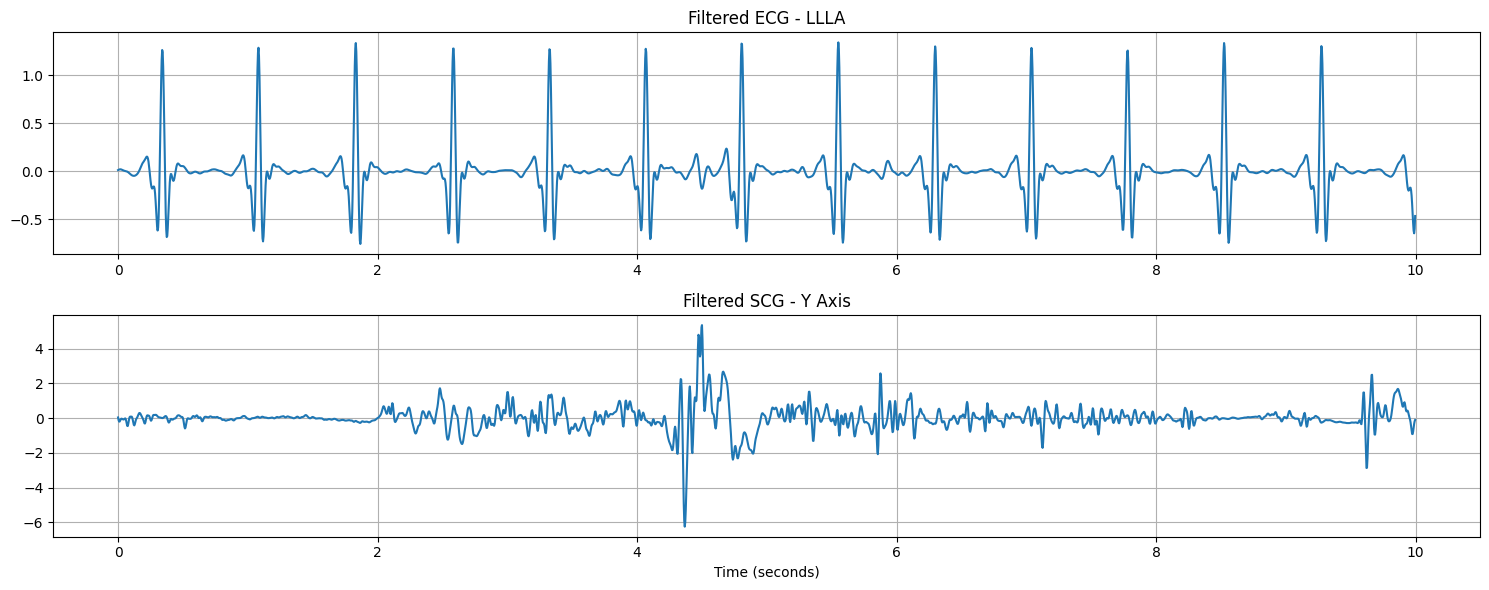

In [ ]:
duration = 10
n = int(duration * fs)
time = np.arange(n) / fs

plt.figure(figsize=(15, 6))

plt.subplot(2, 1, 1)
plt.plot(time, ecg_filtered[:n])
plt.title("Filtered ECG - LLLA")
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(time, scg_filtered[:n])
plt.title("Filtered SCG - Y Axis")
plt.xlabel("Time (seconds)")
plt.grid()

plt.tight_layout()
plt.show()


In [ ]:
# Detect ECG R-peaks
_, rpeaks_info = nk.ecg_peaks(
    ecg_filtered,
    sampling_rate=256
)

rpeaks = rpeaks_info["ECG_R_Peaks"]

print("Total R-peaks detected:", len(rpeaks))
print("First 15 R-peak sample positions:")
print(rpeaks[:15])

print("\nFirst 15 R-peak times (seconds):")
print(np.round(rpeaks[:15] / fs, 3))

Total R-peaks detected: 771
First 15 R-peak sample positions:
[  87  277  469  662  851 1041 1230 1421 1612 1802 1992 2182 2374 2566
 2758]

First 15 R-peak times (seconds):
[ 0.34   1.082  1.832  2.586  3.324  4.066  4.805  5.551  6.297  7.039
  7.781  8.523  9.273 10.023 10.773]


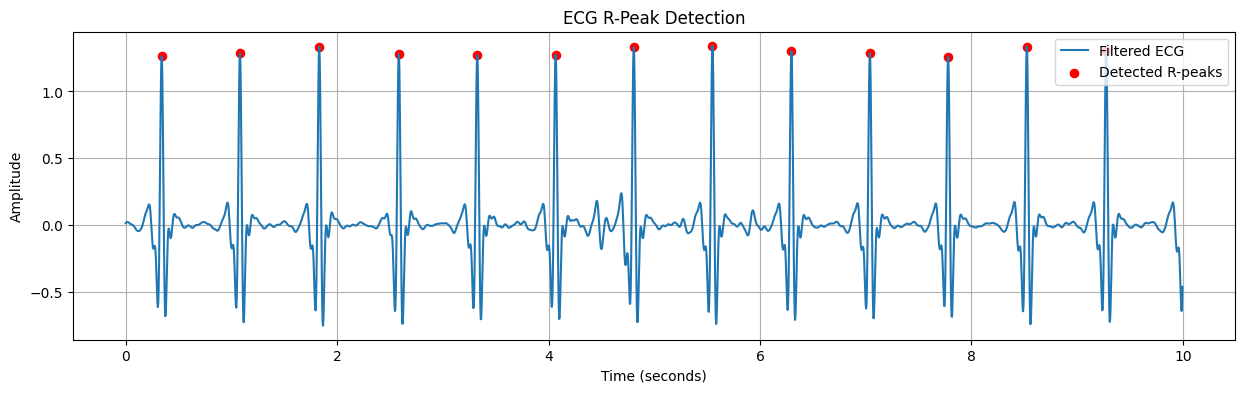

In [ ]:
#Visualize detected R-peaks


plt.figure(figsize=(15, 4))

plt.plot(time, ecg_filtered[:n], label="Filtered ECG")

valid = rpeaks[rpeaks < n]

plt.scatter(
    valid / fs,
    ecg_filtered[valid],
    color="red",
    s=35,
    label="Detected R-peaks"
)

plt.title("ECG R-Peak Detection")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Extract existing ECG annotations
ecg_data = ecg_mat["data"]

R_loc = np.asarray(ecg_data.R_loc).squeeze()
RR_int = np.asarray(ecg_data.RR_int).squeeze()

print("Existing R_loc shape:", R_loc.shape)
print("Existing R_loc first 15 values:")
print(R_loc.flatten()[:15])

print("\nExisting RR_int shape:", RR_int.shape)
print("Existing RR_int first 15 values:")
print(RR_int.flatten()[:15])

print("\nOur detected R-peaks:", len(rpeaks))
print("Existing R_loc count:", R_loc.size)

Existing R_loc shape: (3,)
Existing R_loc first 15 values:
[MatlabOpaque([(b'', b'MCOS', b'duration', array([3707764736,          2,          1,          1,          1,
                               1], dtype=uint32))                                                            ],
              dtype=[('s0', 'O'), ('s1', 'O'), ('s2', 'O'), ('arr', 'O')])
 MatlabOpaque([(b'', b'MCOS', b'duration', array([3707764736,          2,          1,          1,          2,
                               1], dtype=uint32))                                                            ],
              dtype=[('s0', 'O'), ('s1', 'O'), ('s2', 'O'), ('arr', 'O')])
 MatlabOpaque([(b'', b'MCOS', b'duration', array([3707764736,          2,          1,          1,          3,
                               1], dtype=uint32))                                                            ],
              dtype=[('s0', 'O'), ('s1', 'O'), ('s2', 'O'), ('arr', 'O')])                                     ]

Existing RR

In [ ]:

# Inspect RR intervals
print("Number of RR interval arrays:", len(RR_int))

for i, arr in enumerate(RR_int):
    arr = np.asarray(arr).flatten()

    print(f"\nRR array {i+1}")
    print("Number of intervals:", len(arr))
    print("First 10:", arr[:10])
    print("Median RR (ms):", np.median(arr))

# Inspect opaque R_loc objects
for i, obj in enumerate(R_loc):
    print(f"\nR_loc object {i+1}")
    print("Type:", type(obj))
    print("Details:", repr(obj)[:500])

Number of RR interval arrays: 3

RR array 1
Number of intervals: 645
First 10: [742.1875  738.28125 750.      757.8125  796.875   757.8125  773.4375
 773.4375  785.15625 800.78125]
Median RR (ms): 773.4375

RR array 2
Number of intervals: 645
First 10: [742.1875  738.28125 753.90625 757.8125  792.96875 757.8125  773.4375
 773.4375  789.0625  796.875  ]
Median RR (ms): 773.4375

RR array 3
Number of intervals: 645
First 10: [742.1875  738.28125 753.90625 757.8125  792.96875 757.8125  773.4375
 773.4375  789.0625  796.875  ]
Median RR (ms): 773.4375

R_loc object 1
Type: <class 'scipy.io.matlab._mio5_params.MatlabOpaque'>
Details: MatlabOpaque([(b'', b'MCOS', b'duration', array([3707764736,          2,          1,          1,          1,
                              1], dtype=uint32))                                                            ],
             dtype=[('s0', 'O'), ('s1', 'O'), ('s2', 'O'), ('arr', 'O')])

R_loc object 2
Type: <class 'scipy.io.matlab._mio5_params.MatlabOpaq

In [ ]:
#Validate R-peaks and segment SCG cycles


# Calculate RR intervals from detected ECG peaks
detected_rr = np.diff(rpeaks) / fs * 1000

print("Detected RR median:", round(np.median(detected_rr), 2), "ms")
print("Provided RR median:", round(np.median(RR_int[0]), 2), "ms")
print("Detected heart rate:", round(60000 / np.median(detected_rr), 2), "BPM")

# Segment SCG around every ECG R-peak
pre_samples = int(0.200 * fs)
post_samples = int(0.700 * fs)

segments = []
valid_rpeaks = []

for r in rpeaks:
    start = r - pre_samples
    end = r + post_samples

    if start >= 0 and end < len(scg_filtered):
        segment = scg_filtered[start:end]

        segments.append(segment)
        valid_rpeaks.append(r)

segments = np.asarray(segments)
valid_rpeaks = np.asarray(valid_rpeaks)

print("\nSCG segmentation completed!")
print("Valid cardiac cycles:", len(segments))
print("Segment shape:", segments.shape)

Detected RR median: 769.53 ms
Provided RR median: 773.44 ms
Detected heart rate: 77.97 BPM

SCG segmentation completed!
Valid cardiac cycles: 770
Segment shape: (770, 230)


**Visualize individual SCG cycles**

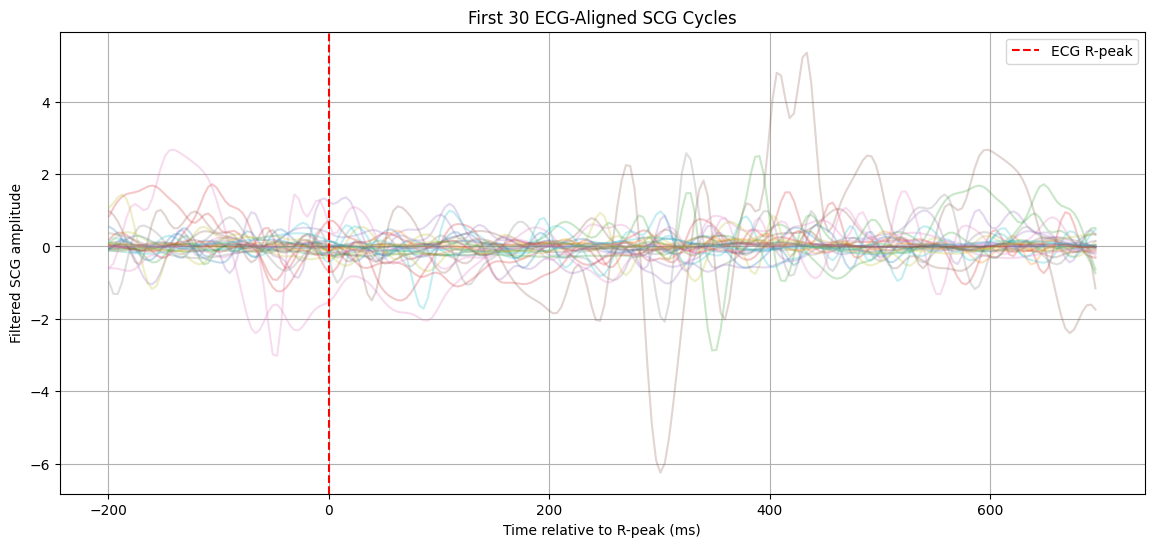

In [ ]:
relative_time = (
    np.arange(segments.shape[1]) - pre_samples
) / fs * 1000

plt.figure(figsize=(14, 6))

for i in range(min(30, len(segments))):
    plt.plot(relative_time, segments[i], alpha=0.25)

plt.axvline(0, color="red", linestyle="--", label="ECG R-peak")
plt.title("First 30 ECG-Aligned SCG Cycles")
plt.xlabel("Time relative to R-peak (ms)")
plt.ylabel("Filtered SCG amplitude")
plt.legend()
plt.grid()
plt.show()


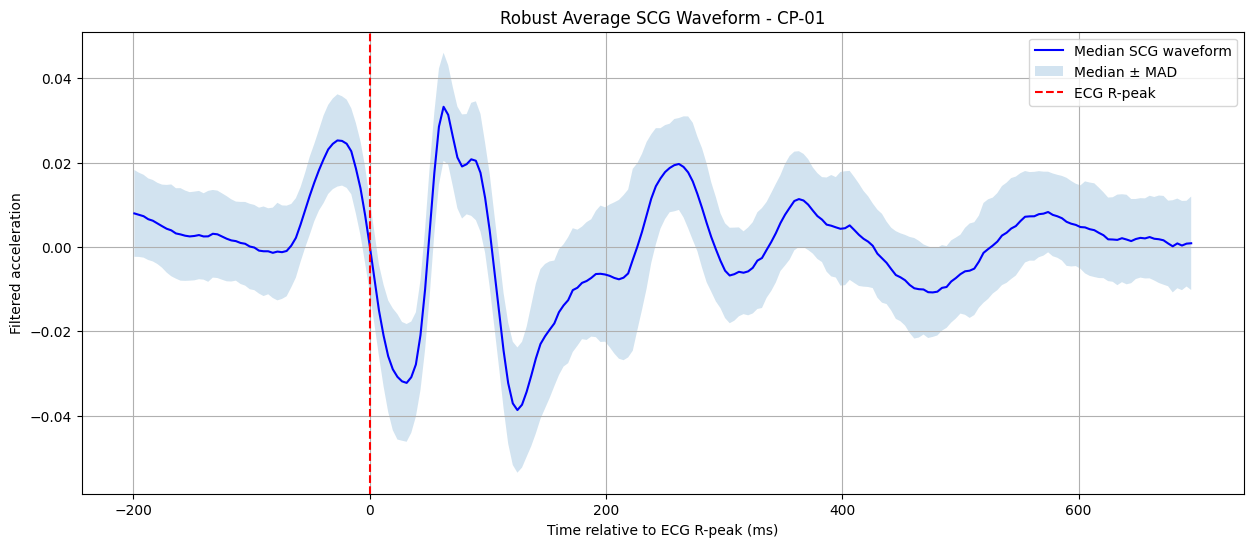

In [ ]:
#Generate a robust average SCG waveform


# Robust average SCG template
average_scg = np.median(segments, axis=0)

# Calculate variability at each time point
scg_mad = median_abs_deviation(
    segments,
    axis=0,
    scale="normal"
)

plt.figure(figsize=(15, 6))

plt.plot(
    relative_time,
    average_scg,
    color="blue",
    label="Median SCG waveform"
)

plt.fill_between(
    relative_time,
    average_scg - scg_mad,
    average_scg + scg_mad,
    alpha=0.2,
    label="Median ± MAD"
)

plt.axvline(0, color="red", linestyle="--", label="ECG R-peak")

plt.title("Robust Average SCG Waveform - CP-01")
plt.xlabel("Time relative to ECG R-peak (ms)")
plt.ylabel("Filtered acceleration")
plt.legend()
plt.grid()
plt.show()

In [ ]:
#Automatic SCG fiducial detection


from scipy.signal import find_peaks

# Reference timings from the 2018 paper (milliseconds after ECG R-peak)
fiducial_reference = {
    "Bs": -111,
    "Cs": -61,
    "Es": 19,
    "Gs": 59,
    "Bd": 348,
    "Hd": 505
}

# Search window around each reference
window_ms = 45

fiducial_results = []

for beat_idx, (segment, r) in enumerate(zip(segments, valid_rpeaks)):

    row = {
        "Beat": beat_idx + 1,
        "R_peak_sample": int(r),
        "R_peak_time_s": r / fs
    }

    for point, reference in fiducial_reference.items():

        left = reference - window_ms
        right = reference + window_ms

        mask = (
            (relative_time >= left) &
            (relative_time <= right)
        )

        indices = np.where(mask)[0]

        if len(indices) == 0:
            row[point + "_sample"] = np.nan
            row[point + "_time_ms"] = np.nan
            continue

        values = segment[indices]

        # Select the strongest local extremum in the search window
        local_max = np.argmax(values)
        local_min = np.argmin(values)

        if abs(values[local_max]) >= abs(values[local_min]):
            selected_idx = indices[local_max]
        else:
            selected_idx = indices[local_min]

        offset_ms = relative_time[selected_idx]
        absolute_sample = int(r + selected_idx - pre_samples)
        row[point + "_sample"] = absolute_sample
        row[point + "_time_ms"] = offset_ms

    fiducial_results.append(row)

fiducial_df = pd.DataFrame(fiducial_results)

print("Fiducial detection completed!")
print("Total beats:", len(fiducial_df))
print(fiducial_df.head())

Fiducial detection completed!
Total beats: 770
   Beat  R_peak_sample  R_peak_time_s  Bs_sample  Bs_time_ms  Cs_sample  \
0     1             87       0.339844         53  -132.81250         74   
1     2            277       1.082031        248  -113.28125        250   
2     3            469       1.832031        449   -78.12500        464   
3     4            662       2.585938        635  -105.46875        635   
4     5            851       3.324219        833   -70.31250        833   

   Cs_time_ms  Es_sample  Es_time_ms  Gs_sample  Gs_time_ms  Bd_sample  \
0   -50.78125        100    50.78125        100    50.78125        166   
1  -105.46875        275    -7.81250        285    31.25000        370   
2   -19.53125        477    31.25000        477    31.25000        561   
3  -105.46875        678    62.50000        679    66.40625        748   
4   -70.31250        855    15.62500        855    15.62500        930   

   Bd_time_ms  Hd_sample  Hd_time_ms  
0   308.59375     

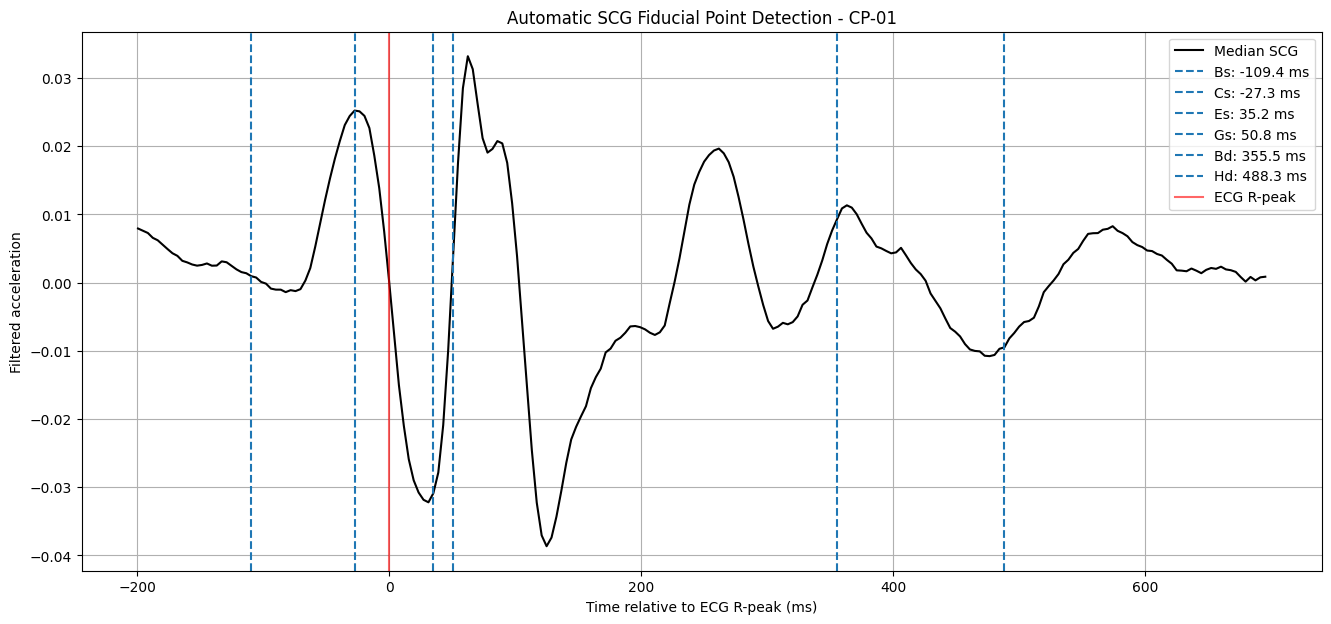

In [ ]:
#Plot all six detected points


plt.figure(figsize=(16, 7))

plt.plot(relative_time, average_scg, color="black", label="Median SCG")

for point in fiducial_reference:

    col = point + "_time_ms"
    detected_time = fiducial_df[col].median()

    plt.axvline(
        detected_time,
        linestyle="--",
        label=f"{point}: {detected_time:.1f} ms"
    )

plt.axvline(0, color="red", alpha=0.6, label="ECG R-peak")

plt.title("Automatic SCG Fiducial Point Detection - CP-01")
plt.xlabel("Time relative to ECG R-peak (ms)")
plt.ylabel("Filtered acceleration")
plt.legend()
plt.grid()
plt.show()

**Final Results**

In [ ]:

# Beat-level results
fiducial_df.to_csv(
    "CP-01_Fiducial_Detections.csv",
    index=False
)

# Summary statistics
summary = fiducial_df.filter(regex="_time_ms$").agg(
    ["mean", "median", "std", "min", "max"]
).T

summary.to_csv("CP-01_Fiducial_Summary.csv")

print("Results exported successfully!")
display(summary)

Results exported successfully!


,mean,median,std,min,max
Bs_time_ms,-108.700284,-109.37500,28.565688,-152.34375,-66.40625
Cs_time_ms,-36.566558,-27.34375,21.739330,-105.46875,-19.53125
Es_time_ms,32.168222,35.15625,27.580544,-23.43750,62.50000
Gs_time_ms,48.894075,50.78125,21.571950,15.62500,101.56250
Bd_time_ms,349.533279,355.46875,27.397110,304.68750,390.62500
Hd_time_ms,496.814123,488.28125,28.764280,460.93750,546.87500


In [ ]:

from google.colab import files

files.download("CP-01_Fiducial_Detections.csv")
files.download("CP-01_Fiducial_Summary.csv")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**New Identification Algorithms**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import butter, filtfilt, find_peaks
from scipy.ndimage import uniform_filter1d

# ==========================================================
# HEFA-2018: HYBRID FIDUCIAL DETECTION
# ==========================================================

# 1. Build a high-frequency acceleration envelope
def highpass(signal, low=25, high=90, fs=256, order=3):
    nyq = fs / 2
    b, a = butter(
        order,
        [low / nyq, high / nyq],
        btype="band"
    )
    return filtfilt(b, a, signal)

# Process all three axes
hx = highpass(x, fs=fs)
hy = highpass(y, fs=fs)
hz = highpass(z, fs=fs)

# Combined high-frequency acceleration
hfacc = np.sqrt(hx**2 + hy**2 + hz**2)
# Smoothed RMS envelope
window = max(3, int(0.040 * fs))
hf_envelope = np.sqrt(
    uniform_filter1d(hfacc**2, size=window)
)

# 2. Reference windows in milliseconds after ECG R-peak
# These are initial search centres, not ground-truth timings.
references = {
    "Bs": -111,
    "Cs": -61,
    "Es": 16,
    "Gs": 59,
    "Bd": 348,
    "Hd": 505
}

search_width = {
    "Bs": 65,
    "Cs": 55,
    "Es": 55,
    "Gs": 55,
    "Bd": 65,
    "Hd": 75
}

# 3. Calculate a robust morphology template
template = np.median(segments, axis=0)
# 4. Candidate-based detection with envelope guidance
results = []

for beat_i, (seg, r) in enumerate(
    zip(segments, valid_rpeaks)
):

    row = {
        "Beat": beat_i + 1,
        "R_peak_sample": int(r),
        "R_peak_time_s": r / fs
    }

    # Extract corresponding HFACC envelope segment
    start = int(r - pre_samples)
    end = start + len(seg)

    env = hf_envelope[start:end]

    for point, ref in references.items():

        width = search_width[point]

        mask = (
            (relative_time >= ref - width) &
            (relative_time <= ref + width)
        )

        idx = np.where(mask)[0]

        if len(idx) < 5:
            row[point + "_sample"] = np.nan
            row[point + "_time_ms"] = np.nan
            row[point + "_confidence"] = 0.0
            continue

        signal_part = seg[idx]
        envelope_part = env[idx]

        # Determine expected polarity from the median template
        template_part = template[idx]
        expected_sign = (
            1 if np.max(template_part) >= abs(np.min(template_part))
            else -1
        )

        # Find both positive and negative local extrema
        peaks, _ = find_peaks(
            expected_sign * signal_part,
            prominence=max(
                np.std(signal_part) * 0.15, 1e-8
            ),
            distance=max(1, int(0.015 * fs))
        )

        # Include a fallback candidate if no local peak exists
        if len(peaks) == 0:
            peaks = np.array([
                np.argmax(expected_sign * signal_part)
            ])

        # Score each candidate using:
        # morphology prominence + HFACC envelope + template agreement
        scores = []
        for p in peaks:
            absolute_idx = idx[p]

            prominence = abs(signal_part[p])
            envelope_score = envelope_part[p]

            morphology_score = abs(
                seg[absolute_idx] - template[absolute_idx]
            )

            # Lower mismatch to template is better
            score = (
                0.55 * prominence /
                (np.max(np.abs(signal_part)) + 1e-8)
                +
                0.30 * envelope_score /
                (np.max(envelope_part) + 1e-8)
                +
                0.15 * (
                    1 - min(
                        morphology_score /
                        (np.std(segments[:, absolute_idx]) + 1e-8),
                        1
                    )
                )
            )

            scores.append(score)

        best = int(np.argmax(scores))
        selected = idx[peaks[best]]
         # Confidence is a relative candidate score
        confidence = float(scores[best])

        row[point + "_sample"] = int(r + selected - pre_samples)
        row[point + "_time_ms"] = float(relative_time[selected])
        row[point + "_confidence"] = confidence

    results.append(row)

hefa_df = pd.DataFrame(results)

# 5. Reject extreme beat-level timing outliers
for point in references:
    col = point + "_time_ms"

    med = hefa_df[col].median()
    mad = np.median(np.abs(hefa_df[col] - med))

    if mad > 0:
        outlier = np.abs(hefa_df[col] - med) > 3 * 1.4826 * mad
        hefa_df.loc[outlier, col] = np.nan
        hefa_df.loc[outlier, point + "_sample"] = np.nan

print("HEFA-2018 detection completed!")
print("Total beats:", len(hefa_df))
print("\nDetected fiducial summary:")
display(
    hefa_df.filter(regex="_time_ms$").agg(
        ["count", "mean", "median", "std", "min", "max"]
    ).T
)

HEFA-2018 detection completed!
Total beats: 770

Detected fiducial summary:


,count,mean,median,std,min,max
Bs_time_ms,770.0,-117.562906,-121.09375,34.591797,-175.78125,-46.87500
Cs_time_ms,698.0,-28.854764,-27.34375,10.574268,-58.59375,-7.81250
Es_time_ms,486.0,61.005015,62.50000,7.092319,27.34375,70.31250
Gs_time_ms,613.0,63.806332,62.50000,4.511775,46.87500,78.12500
Bd_time_ms,757.0,365.866496,363.28125,22.800815,296.87500,410.15625
Hd_time_ms,756.0,484.064980,480.46875,29.172608,433.59375,566.40625


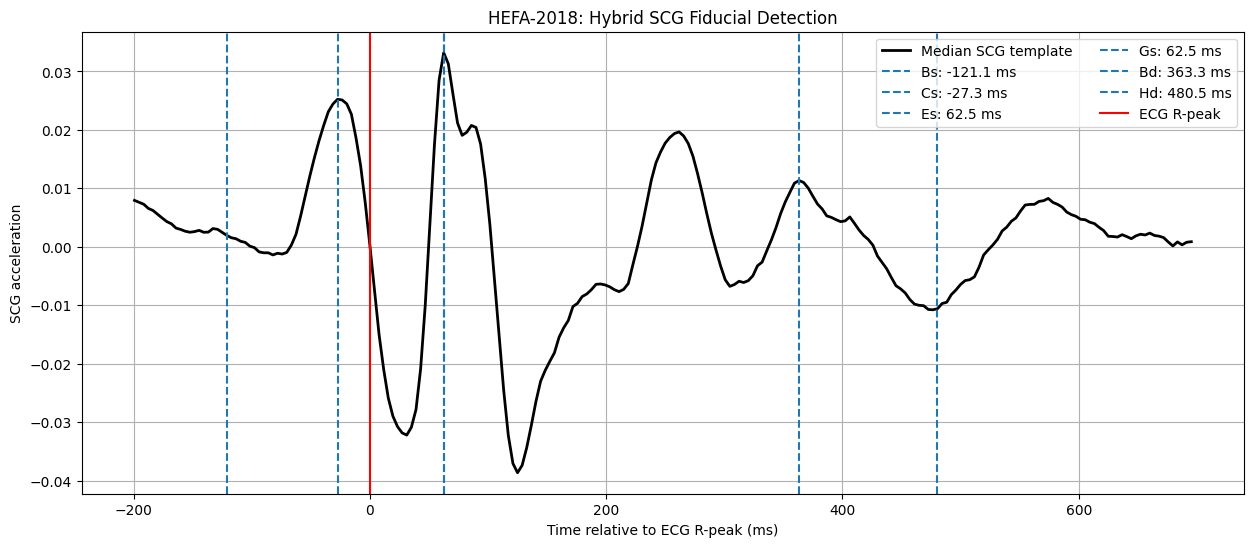

In [ ]:
#New Detections


plt.figure(figsize=(15, 6))

plt.plot(
    relative_time,
    template,
    color="black",
    linewidth=2,
    label="Median SCG template"
)

for point in references:
    detected = hefa_df[point + "_time_ms"].median()

    if np.isfinite(detected):
        plt.axvline(
            detected,
            linestyle="--",
            label=f"{point}: {detected:.1f} ms"
        )

plt.axvline(0, color="red", label="ECG R-peak")

plt.title("HEFA-2018: Hybrid SCG Fiducial Detection")
plt.xlabel("Time relative to ECG R-peak (ms)")
plt.ylabel("SCG acceleration")
plt.legend(ncol=2)
plt.grid()
plt.show()


In [ ]:
#Export the new results

hefa_df.to_csv(
    "CP-01_HEFA2018_Detections.csv",
    index=False
)

hefa_summary = hefa_df.filter(
    regex="_time_ms$"
).agg(["count", "mean", "median", "std", "min", "max"]).T

hefa_summary.to_csv(
    "CP-01_HEFA2018_Summary.csv"
)

from google.colab import files

files.download("CP-01_HEFA2018_Detections.csv")
files.download("CP-01_HEFA2018_Summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>